Práctica 03 · Predicción de deserción al cierre del primer semestre

El objetivo es anticipar si un estudiante estará **graduado (graduate)**,
**desertor (dropout)** o **inscrito (enrolled)** al terminar la duración normal
de su carrera. El instante de decisión es el cierre del primer semestre.
Se utiliza exclusivamente la división del curso: 3539 estudiantes para
entrenamiento y 885 para prueba. No se consultan ni reconstruyen etiquetas de prueba.

La [ficha de UCI](https://archive.ics.uci.edu/dataset/697) documenta 4424
estudiantes, 36 atributos, información de ingreso y resultados de dos semestres.
El periodo 2008/09–2018/19 y la división de entrega corresponden a la consigna.
Las clases son resultados al final de la carrera, no estados al primer semestre.
Los archivos originales provienen del
[repositorio del curso](https://github.com/husseinlopez/icd2026/tree/main/datos).

Este notebook ejecuta todas las búsquedas, genera las gráficas y redacta análisis
con los resultados calculados. Las salidas se guardan también en
`resultados_practica_03/`; el archivo de entrega es `predicciones_desercion.csv`.
Se requiere el entorno de `requirements_practica_03.txt` y ejecutar desde un kernel
nuevo, en orden. La validación anidada implica miles de ajustes y puede tardar.

In [1]:
from pathlib import Path
from time import perf_counter
from datetime import datetime, timezone
from importlib.metadata import version
import hashlib
import json
import os
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import loguniform, randint
from joblib import parallel_config
from sklearn import clone
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, f1_score, make_scorer,
)
from sklearn.model_selection import GridSearchCV, ParameterSampler, StratifiedKFold
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer, KBinsDiscretizer, OneHotEncoder, OrdinalEncoder,
    StandardScaler, MinMaxScaler,
)
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

SEED = 42
SEMILLA_REFINAMIENTO = 2026
CLASES = ['dropout', 'enrolled', 'graduate']
N_EXTERNOS, N_INTERNOS = 5, 3
MIN_CONFIG, MAX_CONFIG, BLOQUE = 80, 160, 40
MIN_REFINADA_FINAL = 120
VENTANA_MESETA, TOL_MESETA = 20, 0.001
N_JOBS = min(8, os.cpu_count() or 1)
assert 50 <= MIN_CONFIG <= MIN_REFINADA_FINAL <= MAX_CONFIG
np.random.seed(SEED)
# Los cuantiles repetidos en conteos producen intervalos redundantes; KBins los fusiona.
warnings.filterwarnings('ignore', message='Bins whose width are too small.*',
                        category=UserWarning)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
LIBRERIAS = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib',
             'joblib', 'threadpoolctl', 'nbformat', 'nbclient', 'ipykernel']
VERSIONES = {'python': platform.python_version(),
             **{lib: version(lib) for lib in LIBRERIAS}}
display(pd.Series(VERSIONES, name='versión').to_frame())

,versión
python,3.12.10
numpy,2.3.5
pandas,2.2.3
scipy,1.18.1
scikit-learn,1.9.1
matplotlib,3.10.8
joblib,1.6.0
threadpoolctl,3.7.0
nbformat,5.10.4
nbclient,0.10.2


Disponibilidad y tipos de atributos

`id` identifica filas y nunca entra al modelo. `Target` es la etiqueta.
Las columnas de prueba definen lo disponible al decidir: 30 atributos del ingreso
y primer semestre. Las seis columnas `2nd sem` están reservadas para el experimento
de espera. No se usan para elegir transformaciones, hiperparámetros o modelos del
primer semestre. El orden de preferencia de ingreso es ordinal; los demás códigos
de categorías se tratan como nominales, incluyendo titulaciones y ocupaciones.
Los códigos de titulaciones mezclan vías educativas y valores desconocidos, por lo
que imponerles el orden numérico original carecería de justificación.

La tabla siguiente describe **cada atributo**. Los nombres y códigos de categorías
se consultan en la [documentación original de UCI](https://archive.ics.uci.edu/dataset/697).
Se conserva `Nacionality`, incluida su grafía original. Un código documentado como
«desconocido» es una categoría; no se convierte arbitrariamente en una medida.

,SHA-256
desercion-entrenamiento.csv,7c477f6b0514318efcc793e69418b7d3e0db5e660eeb5a...
desercion-prueba.csv,c7ba06a34d00a7c8b19a00908760c75914344d18718b25...


,atributo,tipo_semántico,descripción,disponible_desde,dtype,valores_distintos_train,faltantes_train
0,Marital status,Nominal,"Estado civil (1 soltero, 2 casado; otros estad...",Ingreso,int64,6,0
1,Application mode,Nominal,Vía de ingreso; los códigos identifican convoc...,Ingreso,int64,17,0
2,Application order,Ordinal,"Preferencia de ingreso; orden de opciones, no ...",Ingreso,int64,8,0
3,Course,Nominal,Carrera; el código no representa una magnitud.,Ingreso,int64,17,0
4,Daytime/evening attendance,Nominal,"Horario: 1 diurno, 0 nocturno.",Ingreso,int64,2,0
5,Previous qualification,Nominal,Tipo de estudios previos; códigos de vías educ...,Ingreso,int64,17,0
6,Previous qualification (grade),Continua,"Calificación previa, escala 0–200.",Ingreso,float64,100,0
7,Nacionality,Nominal,"Nacionalidad; 1 portuguesa, otros códigos iden...",Ingreso,int64,18,0
8,Mother's qualification,Nominal,"Titulación de la madre, incluyendo categorías ...",Ingreso,int64,26,0
9,Father's qualification,Nominal,"Titulación del padre, incluyendo categorías de...",Ingreso,int64,32,0


,n,porcentaje
Target,,
dropout,1137,32.13
enrolled,635,17.94
graduate,1767,49.93


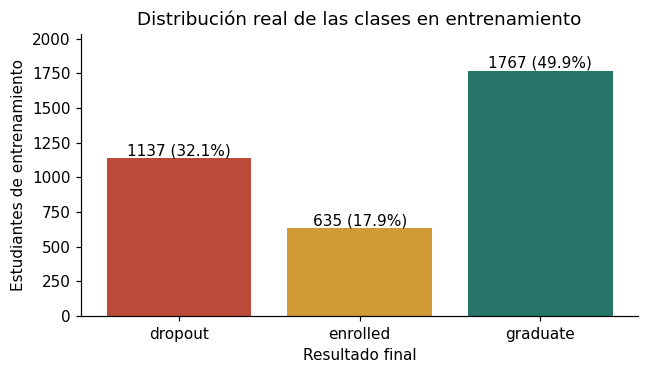

La clase mayoritaria es **graduate** y la minoritaria **enrolled**. Usamos F1 macro para asignar el mismo peso a las tres clases. Entrenamiento contiene 0 valores faltantes en los atributos; prueba contiene 0. Los imputadores permanecen dentro de cada Pipeline como tratamiento reproducible.

In [2]:
# Esquema semántico explícito: no inferir nominal/numérico a partir del dtype.
NOMINALES = {
    'Marital status': 'Estado civil (1 soltero, 2 casado; otros estados codificados).',
    'Application mode': 'Vía de ingreso; los códigos identifican convocatorias o regímenes.',
    'Course': 'Carrera; el código no representa una magnitud.',
    'Daytime/evening attendance': 'Horario: 1 diurno, 0 nocturno.',
    'Previous qualification': 'Tipo de estudios previos; códigos de vías educativas.',
    'Nacionality': 'Nacionalidad; 1 portuguesa, otros códigos identifican países.',
    "Mother's qualification": 'Titulación de la madre, incluyendo categorías desconocidas.',
    "Father's qualification": 'Titulación del padre, incluyendo categorías desconocidas.',
    "Mother's occupation": 'Grupo ocupacional de la madre.',
    "Father's occupation": 'Grupo ocupacional del padre.',
    'Displaced': 'Desplazado: indicador 0/1.',
    'Educational special needs': 'Necesidades educativas especiales: indicador 0/1.',
    'Debtor': 'Deudor: indicador 0/1.',
    'Tuition fees up to date': 'Matrícula al corriente: indicador 0/1.',
    'Gender': 'Género codificado: 1 masculino, 0 femenino, según UCI.',
    'Scholarship holder': 'Becario: indicador 0/1.',
    'International': 'Estudiante internacional: indicador 0/1.',
}
NUMERICAS = {
    'Application order': ('Ordinal', 'Preferencia de ingreso; orden de opciones, no código nominal.'),
    'Previous qualification (grade)': ('Continua', 'Calificación previa, escala 0–200.'),
    'Admission grade': ('Continua', 'Calificación de admisión, escala 0–200.'),
    'Age at enrollment': ('Discreta', 'Edad en años al ingreso.'),
    'Unemployment rate': ('Continua', 'Tasa de desempleo del contexto económico.'),
    'Inflation rate': ('Continua', 'Tasa de inflación del contexto económico.'),
    'GDP': ('Continua', 'Indicador de PIB del contexto económico publicado por UCI.'),
}
for sem in ['1st', '2nd']:
    for atributo, tipo, descripcion in [
        ('credited', 'Discreta', 'Unidades curriculares reconocidas.'),
        ('enrolled', 'Discreta', 'Unidades curriculares inscritas.'),
        ('evaluations', 'Discreta', 'Número de evaluaciones.'),
        ('approved', 'Discreta', 'Unidades curriculares aprobadas.'),
        ('grade', 'Continua', 'Promedio de calificaciones, escala 0–20.'),
        ('without evaluations', 'Discreta', 'Unidades sin evaluación.'),
    ]:
        NUMERICAS[f'Curricular units {sem} sem ({atributo})'] = (tipo, descripcion)

ESQUEMA = set(NOMINALES) | set(NUMERICAS)
SEGUNDO = [c for c in NUMERICAS if '2nd sem' in c]
PRIMERO = ESQUEMA - set(SEGUNDO)
assert (len(ESQUEMA), len(PRIMERO), len(SEGUNDO)) == (36, 30, 6)

def encontrar_directorio():
    candidatos = [Path('datos'), Path('Practicas/datos')]
    for carpeta in candidatos:
        if all((carpeta / n).is_file() for n in
               ['desercion-entrenamiento.csv', 'desercion-prueba.csv']):
            return carpeta
    raise FileNotFoundError(
        'Coloca los dos CSV originales del curso en datos/ o Practicas/datos/. '
        'No se sustituye esta división con el dataset completo de UCI.'
    )

def leer_csv(ruta):
    # id como texto preserva ceros iniciales y evita convertirlo en predictor.
    return pd.read_csv(ruta, dtype={'id': 'string'}, encoding='utf-8-sig')

DATOS = encontrar_directorio()
BASE = DATOS.parent
SALIDAS = BASE / 'resultados_practica_03'
SALIDAS.mkdir(exist_ok=True)
ENTRENAMIENTO = DATOS / 'desercion-entrenamiento.csv'
PRUEBA = DATOS / 'desercion-prueba.csv'
train, test = leer_csv(ENTRENAMIENTO), leer_csv(PRUEBA)
assert train.shape == (3539, 38), f'Entrenamiento inesperado: {train.shape}'
assert test.shape == (885, 31), f'Prueba inesperada: {test.shape}'
assert set(train) == ESQUEMA | {'id', 'Target'}
assert set(test) == PRIMERO | {'id'}
assert 'Target' not in test and not (set(SEGUNDO) & set(test))
assert train.columns.is_unique and test.columns.is_unique
for datos in [train, test]:
    assert datos['id'].notna().all() and datos['id'].is_unique
assert set(train['id']).isdisjoint(test['id']), 'IDs compartidos entre train y test.'

y = train['Target'].astype('string').str.strip().str.lower().astype(str)
assert set(y) == set(CLASES) and not y.isna().any()
columnas_s1 = [c for c in test if c != 'id']
columnas_s2 = columnas_s1 + SEGUNDO
X = train[columnas_s1].apply(pd.to_numeric, errors='raise')
X2 = train[columnas_s2].apply(pd.to_numeric, errors='raise')
X_test = test[columnas_s1].apply(pd.to_numeric, errors='raise')
assert not np.isinf(X2.to_numpy(dtype=float)).any()
assert not np.isinf(X_test.to_numpy(dtype=float)).any()
HUELLAS = {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
           for p in [ENTRENAMIENTO, PRUEBA]}
display(pd.Series(HUELLAS, name='SHA-256').to_frame())

diccionario = pd.DataFrame([
    {'atributo': c,
     'tipo_semántico': 'Nominal' if c in NOMINALES else NUMERICAS[c][0],
     'descripción': NOMINALES[c] if c in NOMINALES else NUMERICAS[c][1],
     'disponible_desde': 'Segundo semestre' if c in SEGUNDO else
                         ('Primer semestre' if '1st sem' in c else 'Ingreso'),
     'dtype': str(train[c].dtype), 'valores_distintos_train': train[c].nunique(),
     'faltantes_train': int(train[c].isna().sum())}
    for c in train if c in ESQUEMA
])
display(diccionario)
diccionario.to_csv(SALIDAS / 'diccionario_atributos.csv', index=False)
distribucion = y.value_counts().reindex(CLASES).rename('n').to_frame()
distribucion['porcentaje'] = 100 * distribucion['n'] / len(y)
display(distribucion.round(2))
distribucion.to_csv(SALIDAS / 'distribucion_clases.csv', index_label='Target')
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(distribucion.index, distribucion['n'], color=['#bb4a39', '#d09a35', '#28756a'])
ax.set(xlabel='Resultado final', ylabel='Estudiantes de entrenamiento',
       title='Distribución real de las clases en entrenamiento')
for i, n in enumerate(distribucion['n']):
    ax.text(i, n, f'{n} ({distribucion.iloc[i]["porcentaje"]:.1f}%)',
            ha='center', va='bottom')
ax.margins(y=0.15)
fig.tight_layout()
fig.savefig(SALIDAS / 'distribucion_clases.png', dpi=180)
plt.show()
display(Markdown(
    f'La clase mayoritaria es **{distribucion["n"].idxmax()}** y la minoritaria '
    f'**{distribucion["n"].idxmin()}**. Usamos F1 macro para asignar el mismo '
    f'peso a las tres clases. Entrenamiento contiene '
    f'{int(X2.isna().sum().sum())} valores faltantes en los atributos; '
    f'prueba contiene {int(X_test.isna().sum().sum())}. '
    'Los imputadores permanecen dentro de cada Pipeline como tratamiento reproducible.'
))

Preprocesamiento por clasificador

El árbol usa imputación y one-hot nominal; no requiere escalamiento y aprende
umbrales de las medidas numéricas. Se optimizan criterio, profundidad, tamaño mínimo
de hoja, poda por complejidad ccp_alpha y pesos de clase.

kNN, SVM y regresión logística usan one-hot nominal y escalan solamente las medidas
numéricas. La fase original compara escalamiento estándar con MinMax (rango 0–1
aprendido en el ajuste y recorte de extremos posteriores). No se estandarizan las
columnas one-hot. kNN busca k, ponderación uniforme o por distancia y distancia
Manhattan o euclidiana. SVM compara kernels lineal y RBF, C, gamma y pesos.
Logística compara L1, L2 y elastic net, C y pesos mediante solvers compatibles con
la pérdida multinomial. En scikit-learn 1.9 la regularización se expresa mediante
l1_ratio: 0 para L2, 1 para L1 e intermedios para elastic net. SAGA usa MinMax y
tolerancia 0.001; LBFGS usa tolerancia 0.0001. Logística conserva one-hot en una
matriz dispersa CSR para reducir operaciones con ceros sin cambiar los valores.

SVM y logística incluyen una segunda fase de búsqueda, dentro del mismo Pipeline.
Compara atributos originales con dos modos de características académicas derivadas.
El modo rates añade aprobadas/inscritas, evaluaciones/inscritas,
unidades sin evaluación/inscritas y un indicador de carga inscrita igual a cero.
El modo rich añade también acreditadas/inscritas, inscritas menos aprobadas y
calificación media multiplicada por la proporción aprobada. Las divisiones con
denominador cero producen NaN, tratados por el imputador del pliegue; el indicador
conserva esa situación. Cada característica usa solo columnas del semestre
disponible: en el modelo de entrega no se generan atributos del segundo semestre.

La fase refinada prueba además pesos relativos 0.75, 1 y 1.5 para el grupo one-hot
frente al grupo numérico, y agrupa opcionalmente categorías con frecuencia menor
a cinco dentro de cada ajuste. Usa escalamiento estándar y concentra SVM en RBF
con C entre 2 y 50 y gamma entre 0.0005 y 0.03; logística usa L2 con LBFGS y C
entre 0.005 y 10. Amplía los pesos de dropout y enrolled, conservando graduate=1,
además de probar None y balanced. La fase original mantiene los kernels, las
regularizaciones y los candidatos iniciales, por lo que la ampliación no los descarta.

Naive Bayes compara GaussianNB con one-hot, escalamiento numérico y var_smoothing,
frente a CategoricalNB con códigos nominales y medidas discretizadas. Busca alpha,
distribución previa, número de intervalos y estrategia. Se reserva el cero para
categorías desconocidas y se desplazan los códigos conocidos en uno: aquí los
enteros indexan probabilidades, no distancias. Los cuantiles repetidos pueden
fusionarse; solo se omite esa advertencia repetitiva. GaussianNB no describe
correctamente indicadores one-hot mediante distribuciones normales; se incluye
como contraste y la validación decide si conviene frente a CategoricalNB.

Todos los imputadores, codificadores, agrupamientos, escaladores y discretizadores
se ajustan exclusivamente con la parte de ajuste de cada pliegue mediante Pipeline
y ColumnTransformer. Las características derivadas no consultan Target ni otros
estudiantes. No se usan ensambles, redes ni etiquetas de prueba.

In [3]:
def academic_features(df, mode='rates'):
    result = df.copy()
    if mode == 'none':
        return result
    for sem in ['1st', '2nd']:
        prefix = f'Curricular units {sem} sem'
        if f'{prefix} (enrolled)' not in result:
            continue
        enrolled = result[f'{prefix} (enrolled)']
        denominator = enrolled.replace(0, np.nan)
        approved = result[f'{prefix} (approved)']
        evaluations = result[f'{prefix} (evaluations)']
        without = result[f'{prefix} (without evaluations)']
        result[f'{sem}_approved_ratio'] = approved / denominator
        result[f'{sem}_evaluations_ratio'] = evaluations / denominator
        result[f'{sem}_without_evaluations_ratio'] = without / denominator
        result[f'{sem}_no_enrollment'] = enrolled.eq(0).astype(int)
        if mode == 'rich':
            result[f'{sem}_credited_ratio'] = result[f'{prefix} (credited)'] / denominator
            result[f'{sem}_not_approved'] = enrolled - approved
            result[f'{sem}_grade_times_progress'] = result[f'{prefix} (grade)'] * approved / denominator
    return result

def categorias_presentes(df):
    return [c for c in df if c in NOMINALES]

def numeros_presentes(df):
    return [c for c in df if c not in NOMINALES]

def sumar_uno(a):
    return np.asarray(a, dtype=np.int64) + 1

def preprocesador(tipo='estandar', disperso=False):
    categorico = Pipeline([
        ('imputar', SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
        ('codificar', OneHotEncoder(handle_unknown='ignore', sparse_output=disperso)),
    ])
    numerico = [('imputar', SimpleImputer(strategy='median', keep_empty_features=True))]
    if tipo == 'estandar':
        numerico.append(('escalar', StandardScaler()))
    elif tipo == 'minmax':
        numerico.append(('escalar', MinMaxScaler(clip=True)))
    return ColumnTransformer([
        ('cat', categorico, categorias_presentes),
        ('num', Pipeline(numerico), numeros_presentes),
    ], remainder='drop', sparse_threshold=1.0 if disperso else 0)

def preprocesador_categorico():
    return Pipeline([
        ('columnas', ColumnTransformer([
            ('cat', Pipeline([
                ('imputar', SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
                ('codificar', OrdinalEncoder(handle_unknown='use_encoded_value',
                                            unknown_value=-1, dtype=np.int64)),
            ]), categorias_presentes),
            ('num', Pipeline([
                ('imputar', SimpleImputer(strategy='median', keep_empty_features=True)),
                ('discretizar', KBinsDiscretizer(
                    n_bins=5, encode='ordinal', strategy='quantile',
                    quantile_method='averaged_inverted_cdf', subsample=None,
                    random_state=SEED)),
            ]), numeros_presentes),
        ], sparse_threshold=0)),
        ('reservar_desconocido', FunctionTransformer(sumar_uno)),
    ])

PESOS = [None, 'balanced',
         {'dropout': 1.0, 'enrolled': 1.5, 'graduate': 1.0},
         {'dropout': 1.2, 'enrolled': 2.0, 'graduate': 1.0}]
ESCALADORES = [StandardScaler(), MinMaxScaler(clip=True)]

# Espacios declarados: las distribuciones log-uniformes cubren varios órdenes.
ESPACIOS = {
    'Árbol': [{
        'modelo': [DecisionTreeClassifier(random_state=SEED)],
        'pre': [preprocesador('ninguno')],
        'modelo__criterion': ['gini', 'entropy', 'log_loss'],
        'modelo__max_depth': [None, 3, 4, 5, 6, 8, 10, 12, 16, 24],
        'modelo__min_samples_leaf': [1, 2, 4, 8, 12, 20, 35],
        'modelo__min_samples_split': [2, 5, 10, 20],
        'modelo__ccp_alpha': [0.0, 0.0001, 0.0003, 0.0007, 0.001, 0.002, 0.005, 0.01],
        'modelo__class_weight': PESOS,
    }],
    'Naive Bayes': [
        {'modelo': [GaussianNB()], 'pre': [preprocesador()],
         'modelo__var_smoothing': loguniform(1e-11, 1.0),
         'pre__num__escalar': ESCALADORES},
        {'modelo': [CategoricalNB()], 'pre': [preprocesador_categorico()],
         'modelo__alpha': loguniform(1e-3, 100),
         'modelo__fit_prior': [True, False],
         'pre__columnas__num__discretizar__n_bins': [3, 4, 5, 7, 10, 15],
         'pre__columnas__num__discretizar__strategy': ['uniform', 'quantile']},
    ],
    'kNN': [{
        'modelo': [KNeighborsClassifier(algorithm='brute', n_jobs=1)],
        'pre': [preprocesador()], 'pre__num__escalar': ESCALADORES,
        'modelo__n_neighbors': randint(3, 82),
        'modelo__weights': ['uniform', 'distance'],
        'modelo__p': [1, 2], 'modelo__metric': ['minkowski'],
    }],
    'SVM': [
        {'modelo': [SVC(kernel=kernel, cache_size=256, random_state=SEED)],
         'pre': [preprocesador()], 'pre__num__escalar': ESCALADORES,
         'modelo__C': loguniform(0.01, 30),
         'modelo__class_weight': PESOS,
         **({'modelo__gamma': loguniform(1e-4, 0.3)} if kernel != 'linear' else {}),
        }
        for kernel in ['linear', 'rbf', 'rbf']
    ],
    'Regresión logística': [
        {'modelo': [LogisticRegression(solver=solver, l1_ratio=ratio,
                                       max_iter=10000,
                                       tol=1e-4 if solver == 'lbfgs' else 1e-3,
                                       random_state=SEED)],
         'pre': [preprocesador(disperso=True)],
         'pre__num__escalar': ESCALADORES if solver == 'lbfgs' else [MinMaxScaler(clip=True)],
         'modelo__C': loguniform(1e-3, 30), 'modelo__class_weight': PESOS}
        for solver, ratio in [('lbfgs', 0.0), ('saga', 1.0), ('saga', 0.5)]
    ],
}

def muestrear_candidatos(grupos, cantidad=MAX_CONFIG):
    rng = np.random.RandomState(SEED)
    candidatos, vistos = [], set()
    while len(candidatos) < cantidad:
        # Intercalar grupos garantiza presencia de variantes desde el primer bloque.
        for i in rng.permutation(len(grupos)):
            semilla = int(rng.randint(0, 2**31 - 1))
            p = list(ParameterSampler(grupos[i], n_iter=1, random_state=semilla))[0]
            firma = repr(sorted((k, repr(v)) for k, v in p.items()))
            if firma not in vistos:
                vistos.add(firma)
                candidatos.append(p)
            if len(candidatos) == cantidad:
                break
    return candidatos

CANDIDATOS = {nombre: muestrear_candidatos(grupos)
              for nombre, grupos in ESPACIOS.items()}
pipeline_base = Pipeline([('features', 'passthrough'),
                          ('pre', preprocesador()),
                          ('modelo', DecisionTreeClassifier(random_state=SEED))])
SCORER = make_scorer(f1_score, average='macro', labels=CLASES, zero_division=0)

def construir_estimador(parametros):
    # Clonar ANTES de set_params evita modificar objetos compartidos del espacio.
    configuracion = clone(parametros, safe=False)
    return clone(pipeline_base).set_params(**configuracion)

def legible(parametros, incluir_pipeline=True):
    estimador = construir_estimador(parametros)
    efectivos = estimador.get_params(deep=True)
    def valor_legible(valor):
        if isinstance(valor, np.generic):
            return valor.item()
        if isinstance(valor, (str, int, float, bool, dict, type(None))):
            return valor
        return repr(valor)
    resultado = {k: valor_legible(efectivos[k]) for k in parametros}
    # Los repr de componentes ya incluyen todos los valores con prefijo aplicados.
    for paso in ['features', 'pre', 'modelo']:
        resultado[paso] = valor_legible(estimador.named_steps[paso])
    if incluir_pipeline:
        resultado['pipeline_efectivo'] = repr(estimador)
    return resultado

PESOS_REFINADOS = [None, 'balanced'] + [
    {'dropout': d, 'enrolled': e, 'graduate': 1.0}
    for d in [0.8, 1.0, 1.2, 1.5] for e in [1.25, 1.75, 2.0, 2.5]
]

def espacio_refinado(logistica=False):
    # Se conservan estas claves y su muestreo para reproducir los experimentos.
    espacio = {
        'features__kw_args': [{'mode': m} for m in ['none', 'rates', 'rich']],
        'pre__transformer_weights': [{'cat': w, 'num': 1.0} for w in [0.75, 1.0, 1.5]],
        'pre__cat__encode__min_frequency': [None, 5],
        'model__class_weight': PESOS_REFINADOS,
        'model__C': loguniform(0.005, 10) if logistica else loguniform(2, 50),
    }
    if not logistica:
        espacio['model__gamma'] = loguniform(0.0005, 0.03)
    return espacio

def nombre_parametro_refinado(nombre):
    if nombre.startswith('model__'):
        nombre = 'modelo__' + nombre.removeprefix('model__')
    return nombre.replace('pre__cat__encode__', 'pre__cat__codificar__')

def componentes_refinados(logistica=False):
    modelo = (
        LogisticRegression(solver='lbfgs', l1_ratio=0.0, max_iter=10000,
                           tol=1e-4, random_state=SEED)
        if logistica else SVC(kernel='rbf', cache_size=256, random_state=SEED)
    )
    return {
        'features': FunctionTransformer(academic_features),
        'pre': preprocesador(disperso=logistica),
        'modelo': modelo,
    }

def candidatos_refinados(logistica=False, cantidad=MAX_CONFIG):
    espacio = espacio_refinado(logistica)
    muestras = list(ParameterSampler(espacio, n_iter=cantidad - 3,
                                    random_state=SEMILLA_REFINAMIENTO))
    referencia = {
        'features__kw_args': {'mode': 'none'},
        'pre__transformer_weights': {'cat': 1.0, 'num': 1.0},
        'pre__cat__encode__min_frequency': None,
        'model__class_weight': {'dropout': 1.2, 'enrolled': 2.0, 'graduate': 1.0},
        'model__C': 0.0416031769123584 if logistica else 12.59082755243927,
    }
    if not logistica:
        referencia['model__gamma'] = 0.003419867290052566
    anclas = [dict(referencia, features__kw_args={'mode': m})
              for m in ['none', 'rates', 'rich']]
    candidatos = []
    for parametros in anclas + muestras:
        configuracion = componentes_refinados(logistica)
        configuracion.update({
            nombre_parametro_refinado(k): v for k, v in parametros.items()
        })
        candidatos.append(clone(configuracion, safe=False))
    return candidatos

NOMBRE_LOGISTICA = 'Regresión logística'
CANDIDATOS_REFINADOS = {
    'SVM': candidatos_refinados(False),
    NOMBRE_LOGISTICA: candidatos_refinados(True),
}
ESPACIOS_REFINADOS = {
    nombre: {
        **componentes_refinados(logistica),
        **{nombre_parametro_refinado(k): v
           for k, v in espacio_refinado(logistica).items()},
    }
    for nombre, logistica in [('SVM', False), (NOMBRE_LOGISTICA, True)]
}
FASES = {
    nombre: [('original', CANDIDATOS[nombre])] +
            ([('refinada', CANDIDATOS_REFINADOS[nombre])]
             if nombre in CANDIDATOS_REFINADOS else [])
    for nombre in ESPACIOS
}

display(pd.DataFrame([
    {'clasificador': nombre, 'fases': len(fases),
     'configuraciones_minimas_busqueda_anidada': MIN_CONFIG * len(fases),
     'configuraciones_minimas_busqueda_final':
         MIN_CONFIG + (MIN_REFINADA_FINAL if len(fases) == 2 else 0),
     'configuraciones_maximas_por_busqueda': MAX_CONFIG * len(fases)}
    for nombre, fases in FASES.items()
]))
# Se exportan los espacios y las listas completas, incluidos los candidatos no usados.
(SALIDAS / 'espacios_y_candidatos.json').write_text(json.dumps(
    {
        'semillas': {'original': SEED, 'refinada': SEMILLA_REFINAMIENTO},
        'presupuesto_por_fase': {
            'minimo_original': MIN_CONFIG,
            'minimo_refinado_anidado': MIN_CONFIG,
            'minimo_refinado_final': MIN_REFINADA_FINAL,
            'maximo_cada_fase': MAX_CONFIG,
        },
        'fases_por_familia': {n: [f for f, _ in fases] for n, fases in FASES.items()},
        'espacios': {n: repr(g) for n, g in ESPACIOS.items()},
        'espacios_refinados': {n: repr(g) for n, g in ESPACIOS_REFINADOS.items()},
        'candidatos': {n: [legible(p, incluir_pipeline=False) for p in ps]
                       for n, ps in CANDIDATOS.items()},
        'candidatos_refinados': {n: [legible(p, incluir_pipeline=False) for p in ps]
                                 for n, ps in CANDIDATOS_REFINADOS.items()},
    },
    ensure_ascii=False, indent=2), encoding='utf-8')

,clasificador,fases,configuraciones_minimas_busqueda_anidada,configuraciones_minimas_busqueda_final,configuraciones_maximas_por_busqueda
0,Árbol,1,80,80,160
1,Naive Bayes,1,80,80,160
2,kNN,1,80,80,160
3,SVM,2,160,200,320
4,Regresión logística,2,160,200,320


1984741

Optimización y evaluación

La evaluación usa cinco pliegues externos estratificados y comunes a los cinco
clasificadores. Dentro de cada parte de ajuste se optimiza con tres pliegues internos,
también comunes. Cada estudiante recibe una predicción externa de un modelo cuyos
hiperparámetros y preprocesamiento se eligieron sin utilizar su etiqueta en cada búsqueda interna. La comparación
principal informa media y desviación estándar muestral de esos cinco F1 externos.
La [validación anidada](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html)
separa la selección de hiperparámetros de su evaluación.

Cada fase evalúa al menos 80 candidatos, en un orden reproducible, y puede ampliarse
en bloques de 40 hasta 160. Se detiene si el mejor F1 no mejoró más de 0.001 en
las últimas 20 configuraciones de esa fase. La fase original usa semilla 42; el
muestreo refinado usa 2026 y comienza con tres referencias: atributos originales,
rates y rich. La lista se prepara con ParameterSampler y cada bloque se evalúa con
GridSearchCV, sin un producto cartesiano adicional.

Árbol, Naive Bayes y kNN tienen una sola fase original: al menos 80 candidatos por
búsqueda, hasta 160. SVM y logística ejecutan las fases original y refinada dentro
de cada partición interna: al menos 160 candidatos en total, hasta 320. Se elige la
configuración con mayor F1 interno entre ambas fases; no se combinan predicciones.
Cada fase tiene su propia comprobación de meseta y el resultado solo declara meseta
si todas sus fases la cumplieron. Una meseta no garantiza el óptimo global.

Después se optimizan las cinco familias sobre todo entrenamiento, con los mismos
cinco pliegues. Para las búsquedas finales de SVM y logística se eleva el mínimo
refinado a 120, conservando 80 en la fase original: al menos 200 candidatos y hasta
320. Ese presupuesto adicional se declara como selección final, no como una nueva
estimación externa. Los otros tres modelos mantienen su presupuesto de 80–160.

Estas búsquedas finales producen curvas y parámetros para el ajuste de entrega;
sus scores de selección no reemplazan los resultados externos. La familia final
se elige por mayor F1 externo medio; en empates exactos se conserva el orden de la
comparación. Elegir entre familias y ampliar espacios después de observar resultados
puede introducir optimismo de desarrollo; la prueba del curso será la evaluación final.

In [4]:
CV_EXTERNA = list(StratifiedKFold(
    n_splits=N_EXTERNOS, shuffle=True, random_state=SEED).split(X, y))
CV_INTERNA = [list(StratifiedKFold(
    n_splits=N_INTERNOS, shuffle=True, random_state=SEED + i + 1
).split(X.iloc[ajuste], y.iloc[ajuste])) for i, (ajuste, _) in enumerate(CV_EXTERNA)]
asignacion = np.full(len(y), -1, dtype=int)
for i, (_, validacion) in enumerate(CV_EXTERNA):
    asignacion[validacion] = i + 1
assert (asignacion >= 1).all()
pd.DataFrame({'id': train['id'], 'pliegue_externo': asignacion}).to_csv(
    SALIDAS / 'pliegues.csv', index=False)

def buscar(nombre, datos, etiquetas, cv, minimo=MIN_CONFIG, maximo=MAX_CONFIG,
           minimo_refinado=None):
    inicio = perf_counter()
    minimo_refinado = minimo if minimo_refinado is None else minimo_refinado
    assert VENTANA_MESETA < minimo <= maximo <= MAX_CONFIG
    assert VENTANA_MESETA < minimo_refinado <= maximo
    historiales = []
    detalle_fases = []
    total = 0
    for fase, candidatos in FASES[nombre]:
        inicio_fase = perf_counter()
        minimo_fase = minimo_refinado if fase == 'refinada' else minimo
        bloques = []
        cantidad = 0
        print(f'{nombre} / {fase}: inicio, minimo={minimo_fase}, maximo={maximo}',
              flush=True)
        while cantidad < maximo:
            limite = min(minimo_fase if cantidad == 0 else cantidad + BLOQUE, maximo)
            rejilla = [
                {k: [v] for k, v in clone(p, safe=False).items()}
                for p in candidatos[cantidad:limite]
            ]
            busqueda = GridSearchCV(
                clone(pipeline_base), param_grid=rejilla, scoring=SCORER, cv=cv,
                n_jobs=N_JOBS, refit=False, return_train_score=False,
                error_score='raise', pre_dispatch=N_JOBS)
            with warnings.catch_warnings(), threadpool_limits(limits=1), parallel_config(
                    backend='threading'):
                warnings.simplefilter('error', ConvergenceWarning)
                busqueda.fit(datos, etiquetas)
            bloque = pd.DataFrame(busqueda.cv_results_)
            bloque['fase'] = fase
            bloque['configuracion_fase'] = np.arange(cantidad + 1, limite + 1)
            bloque['configuracion_global'] = np.arange(total + cantidad + 1,
                                                       total + limite + 1)
            bloques.append(bloque)
            cantidad = limite
            historial_fase = pd.concat(bloques, ignore_index=True)
            scores_fase = historial_fase['mean_test_score'].to_numpy()
            assert np.isfinite(scores_fase).all(), 'Score no finito o ajuste fallido.'
            acumulado_fase = np.maximum.accumulate(scores_fase)
            ganancia = float(acumulado_fase[-1] -
                             acumulado_fase[-VENTANA_MESETA - 1])
            meseta_fase = ganancia <= TOL_MESETA
            print(f'{nombre} / {fase}: {cantidad} configuraciones, '
                  f'mejor F1={scores_fase.max():.6f}, ganancia={ganancia:.6f}',
                  flush=True)
            if meseta_fase:
                break
        historiales.append(historial_fase)
        detalle_fases.append({
            'fase': fase, 'n_config': cantidad, 'minimo': minimo_fase,
            'maximo': maximo, 'meseta': bool(meseta_fase),
            'ganancia_cola': ganancia,
            'mejor_f1_seleccion': float(scores_fase.max()),
            'segundos': perf_counter() - inicio_fase,
        })
        total += cantidad
    historial = pd.concat(historiales, ignore_index=True)
    scores = historial['mean_test_score'].to_numpy()
    indice = int(np.argmax(scores))
    return {
        'params': clone(historial.iloc[indice]['params'], safe=False),
        'historial': historial, 'f1_seleccion': float(scores[indice]),
        'n_config': total, 'meseta': all(f['meseta'] for f in detalle_fases),
        'ganancia_cola': max(f['ganancia_cola'] for f in detalle_fases),
        'fase_seleccionada': str(historial.iloc[indice]['fase']),
        'fases': detalle_fases, 'segundos': perf_counter() - inicio,
    }

def metricas_clase(reales, predichas):
    cm = confusion_matrix(reales, predichas, labels=CLASES)
    tp = np.diag(cm)
    fn, fp = cm.sum(axis=1) - tp, cm.sum(axis=0) - tp
    tn = cm.sum() - tp - fn - fp
    return pd.DataFrame({'clase': CLASES,
        'sensibilidad': np.divide(tp, tp + fn, out=np.zeros(3, dtype=float), where=tp+fn != 0),
        'especificidad': np.divide(tn, tn + fp, out=np.zeros(3, dtype=float), where=tn+fp != 0)})

def evaluar_anidado(nombre, datos):
    inicio = perf_counter()
    predicciones = np.empty(len(y), dtype=object)
    visitas = np.zeros(len(y), dtype=int)
    filas, detalles, seleccion, busquedas_externas = [], [], [], []
    for i, (ajuste, validacion) in enumerate(CV_EXTERNA):
        resultado = buscar(nombre, datos.iloc[ajuste], y.iloc[ajuste], CV_INTERNA[i])
        estimador = construir_estimador(resultado['params'])
        with threadpool_limits(limits=1), warnings.catch_warnings():
            warnings.simplefilter('error', ConvergenceWarning)
            estimador.fit(datos.iloc[ajuste], y.iloc[ajuste])
            pred = estimador.predict(datos.iloc[validacion])
        predicciones[validacion] = pred
        visitas[validacion] += 1
        f1 = f1_score(y.iloc[validacion], pred, labels=CLASES,
                      average='macro', zero_division=0)
        filas.append({'modelo': nombre, 'pliegue': i + 1, 'f1_macro': f1,
                      'segundos_busqueda': resultado['segundos'],
                      'n_config': resultado['n_config'], 'meseta': resultado['meseta'],
                      'fase_seleccionada': resultado['fase_seleccionada'],
                      'configuraciones_por_fase': json.dumps({
                          f['fase']: f['n_config'] for f in resultado['fases']})})
        m = metricas_clase(y.iloc[validacion], pred)
        m['modelo'], m['pliegue'] = nombre, i + 1
        detalles.append(m)
        seleccion.append(legible(resultado['params']))
        busquedas_externas.append({'pliegue': i + 1,
            'fase_seleccionada': resultado['fase_seleccionada'],
            'fases': resultado['fases']})
        print(f'{nombre}: externo {i+1}/{N_EXTERNOS}, F1={f1:.4f}, '
              f'configuraciones={resultado["n_config"]}', flush=True)
    assert np.all(visitas == 1) and set(predicciones) <= set(CLASES)
    return {'oof': predicciones, 'pliegues': pd.DataFrame(filas),
            'clases': pd.concat(detalles, ignore_index=True),
            'parametros_externos': seleccion, 'busquedas_externas': busquedas_externas,
            'segundos_total': perf_counter() - inicio}

Árbol / original: inicio, minimo=80, maximo=160


Árbol / original: 80 configuraciones, mejor F1=0.640947, ganancia=0.000000


Árbol: externo 1/5, F1=0.6385, configuraciones=80


Árbol / original: inicio, minimo=80, maximo=160


Árbol / original: 80 configuraciones, mejor F1=0.641981, ganancia=0.000000


Árbol: externo 2/5, F1=0.6331, configuraciones=80


... (89 outputs left out)

Regresión logística / refinada: 80 configuraciones, mejor F1=0.686385, ganancia=0.000000


Regresión logística: externo 5/5, F1=0.6900, configuraciones=160


,f1_macro_media,f1_macro_std,segundos_busqueda_anidada,configuraciones_anidadas,f1_macro_oof
modelo,,,,,
SVM,0.6883,0.0106,765.9190,800,0.6886
Regresión logística,0.6842,0.0057,184.6773,880,0.6851
Árbol,0.6378,0.0128,38.1034,400,0.6389
Naive Bayes,0.6104,0.0118,27.0028,400,0.6108
kNN,0.5627,0.0121,78.3364,400,0.5630


sensibilidad_media  sensibilidad_std  \
modelo              clase                                            
Árbol               dropout               0.6297            0.0369   
                    enrolled              0.4205            0.0808   
                    graduate              0.8517            0.0456   
Naive Bayes         dropout               0.6569            0.0328   
                    enrolled              0.5008            0.0636   
                    graduate              0.7012            0.0318   
kNN                 dropout               0.5831            0.0362   
                    enrolled              0.1984            0.0225   
                    graduate              0.8936            0.0152   
SVM                 dropout               0.6799            0.0357   
                    enrolled              0.5134            0.0549   
                    graduate              0.8659            0.0238   
Regresión logística dropout               0.7009            0.0303   
                    enrolled              0.5402            0.0914   
                    graduate              0.8212            0.0373   

                              especificidad_media  especificidad_std  
modelo              clase                                             
Árbol               dropout                0.9325             0.0174  
                    enrolled               0.8454             0.0321  
                    graduate               0.7517             0.0446  
Naive Bayes         dropout                0.8410             0.0197  
                    enrolled               0.8168             0.0358  
                    graduate               0.8189             0.0189  
kNN                 dropout                0.9092             0.0155  
                    enrolled               0.9277             0.0084  
                    graduate               0.5807             0.0199  
SVM                 dropout                0.9338             0.0168  
                    enrolled               0.8640             0.0258  
                    graduate               0.7991             0.0138  
Regresión logística dropout                0.9242             0.0199  
                    enrolled               0.8461             0.0312  
                    graduate               0.8200             0.0311

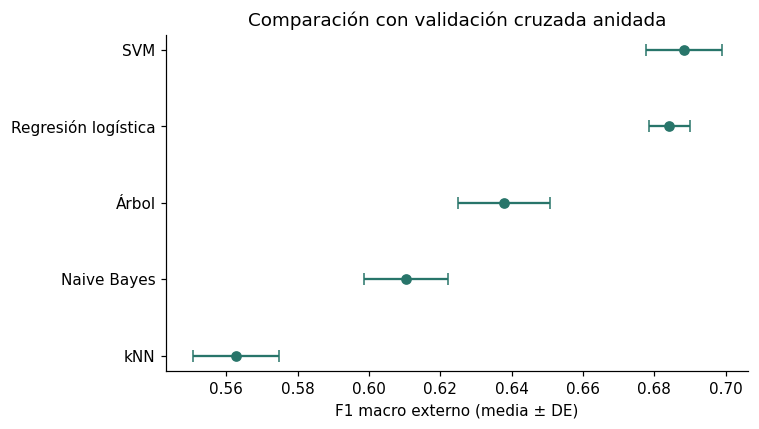

La mayor media externa corresponde a **SVM**, con **0.6883 ± 0.0106**. La desviación describe variación entre pliegues; no es un intervalo de confianza. F1 calculado sobre todo OOF puede diferir de la media porque F1 no es lineal. La sensibilidad es TP/(TP+FN); la especificidad TN/(TN+FP), considerando cada clase contra las otras dos.

In [5]:
resultados_cv = {}
for nombre in ESPACIOS:
    resultados_cv[nombre] = evaluar_anidado(nombre, X)
    r = resultados_cv[nombre]
    slug = list(ESPACIOS).index(nombre) + 1
    r['pliegues'].to_csv(SALIDAS / f'cv_modelo_{slug}.csv', index=False)

pliegues = pd.concat([r['pliegues'] for r in resultados_cv.values()], ignore_index=True)
por_clase = pd.concat([r['clases'] for r in resultados_cv.values()], ignore_index=True)
comparacion = pliegues.groupby('modelo', sort=False).agg(
    f1_macro_media=('f1_macro', 'mean'), f1_macro_std=('f1_macro', 'std'),
    segundos_busqueda_anidada=('segundos_busqueda', 'sum'),
    configuraciones_anidadas=('n_config', 'sum'),
).sort_values('f1_macro_media', ascending=False, kind='stable')
comparacion['f1_macro_oof'] = [f1_score(y, resultados_cv[n]['oof'],
    labels=CLASES, average='macro', zero_division=0) for n in comparacion.index]
mejor_nombre = comparacion.index[0]
display(comparacion.round(4))
metricas = por_clase.groupby(['modelo', 'clase'], sort=False).agg(
    sensibilidad_media=('sensibilidad', 'mean'), sensibilidad_std=('sensibilidad', 'std'),
    especificidad_media=('especificidad', 'mean'), especificidad_std=('especificidad', 'std'))
display(metricas.round(4))
pliegues.to_csv(SALIDAS / 'metricas_pliegues.csv', index=False)
metricas.to_csv(SALIDAS / 'sensibilidad_especificidad.csv')
oof = pd.DataFrame({'id': train['id'], 'Target_real': y,
                    'pliegue': asignacion,
                    **{n: r['oof'] for n, r in resultados_cv.items()}})
oof.to_csv(SALIDAS / 'predicciones_oof.csv', index=False)

fig, ax = plt.subplots(figsize=(7, 4))
pos = np.arange(len(comparacion))
ax.errorbar(comparacion['f1_macro_media'], pos,
            xerr=comparacion['f1_macro_std'], fmt='o', capsize=4, color='#28756a')
ax.set(yticks=pos, yticklabels=comparacion.index, xlabel='F1 macro externo (media ± DE)',
       title='Comparación con validación cruzada anidada')
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(SALIDAS / 'comparacion_modelos.png', dpi=180)
plt.show()
display(Markdown(
    f'La mayor media externa corresponde a **{mejor_nombre}**, con '
    f'**{comparacion.iloc[0]["f1_macro_media"]:.4f} ± '
    f'{comparacion.iloc[0]["f1_macro_std"]:.4f}**. '
    'La desviación describe variación entre pliegues; no es un intervalo de confianza. '
    'F1 calculado sobre todo OOF puede diferir de la media porque F1 no es lineal. '
    'La sensibilidad es TP/(TP+FN); la especificidad TN/(TN+FP), '
    'considerando cada clase contra las otras dos.'
))

Búsquedas sobre todo entrenamiento y verificación de meseta

Los cinco modelos comparten exactamente los mismos pliegues de selección final.
Árbol, Naive Bayes y kNN evalúan una fase de 80–160 configuraciones. SVM y
logística evalúan una fase original de 80–160 y otra refinada de 120–160:
su mínimo final es 200 y su máximo 320. En cada fase se conserva el orden de los
candidatos y se comprueba su meseta por separado; se registra cuántos se evaluaron.

Las curvas muestran F1 macro de validación del mejor candidato acumulado; las marcas
verticales separan fases y las zonas sombreadas identifican la cola de cada una.
La tabla incluye la ganancia máxima de las últimas 20 configuraciones por fase.
Solo se declara meseta conjunta cuando todas las fases satisfacen el criterio.
Los scores son de selección, no desempeño de prueba ni una nueva evaluación externa.
Si se alcanza el límite sin meseta, se indica expresamente.

Búsqueda final: Árbol


Árbol / original: inicio, minimo=80, maximo=160


Árbol / original: 80 configuraciones, mejor F1=0.650703, ganancia=0.000000


Búsqueda final: Naive Bayes


Naive Bayes / original: inicio, minimo=80, maximo=160


Naive Bayes / original: 80 configuraciones, mejor F1=0.624234, ganancia=0.000000


... (10 outputs left out)

Regresión logística / original: 80 configuraciones, mejor F1=0.681924, ganancia=0.000000


Regresión logística / refinada: inicio, minimo=120, maximo=160


Regresión logística / refinada: 120 configuraciones, mejor F1=0.691368, ganancia=0.000000


,n_config,mejor_f1_seleccion,ganancia_maxima_cola_por_fase,meseta,fase_seleccionada,configuraciones_por_fase,segundos_busqueda_final
modelo,,,,,,,
Árbol,80,0.65070,0.0,True,original,"{""original"": 80}",12.77881
Naive Bayes,80,0.62423,0.0,True,original,"{""original"": 80}",9.42345
kNN,80,0.56396,0.0,True,original,"{""original"": 80}",29.73598
SVM,200,0.69183,0.0,True,refinada,"{""original"": 80, ""refinada"": 120}",677.72039
Regresión logística,200,0.69137,0.0,True,refinada,"{""original"": 80, ""refinada"": 120}",90.27692


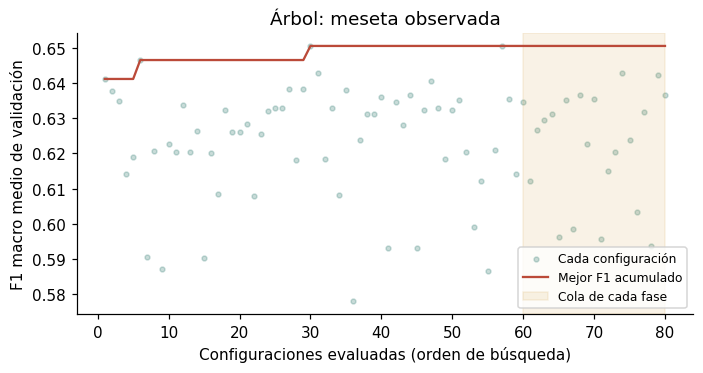

**Árbol: parámetros elegidos por validación.**

,valor
modelo,"DecisionTreeClassifier(ccp_alpha=0.0007,\n ..."
modelo__ccp_alpha,0.0007
modelo__class_weight,"{'dropout': 1.0, 'enrolled': 1.5, 'graduate': ..."
modelo__criterion,gini
modelo__max_depth,16
modelo__min_samples_leaf,35
modelo__min_samples_split,20
pre,"ColumnTransformer(sparse_threshold=0,\n ..."
features,passthrough
pipeline_efectivo,"Pipeline(steps=[('features', 'passthrough'),\n..."


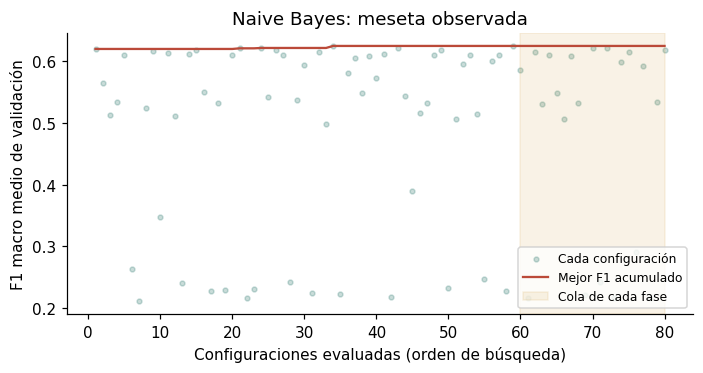

**Naive Bayes: parámetros elegidos por validación.**

,valor
modelo,CategoricalNB(alpha=np.float64(0.0082928994617...
modelo__alpha,0.008293
modelo__fit_prior,True
pre,"Pipeline(steps=[('columnas',\n ..."
pre__columnas__num__discretizar__n_bins,4
pre__columnas__num__discretizar__strategy,quantile
features,passthrough
pipeline_efectivo,"Pipeline(steps=[('features', 'passthrough'),\n..."


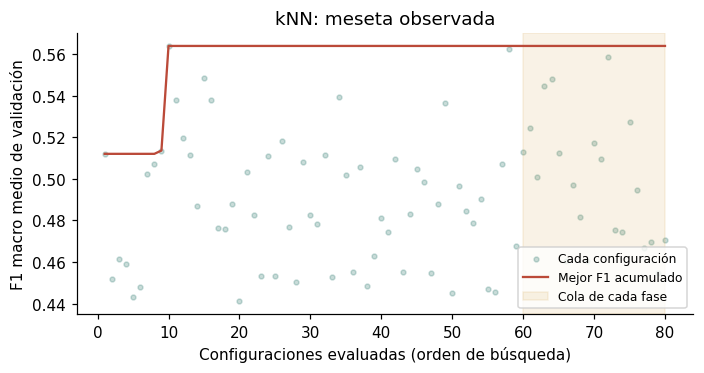

**kNN: parámetros elegidos por validación.**

,valor
modelo,"KNeighborsClassifier(algorithm='brute', n_jobs..."
modelo__metric,minkowski
modelo__n_neighbors,11
modelo__p,2
modelo__weights,distance
pre,"ColumnTransformer(sparse_threshold=0,\n ..."
pre__num__escalar,StandardScaler()
features,passthrough
pipeline_efectivo,"Pipeline(steps=[('features', 'passthrough'),\n..."


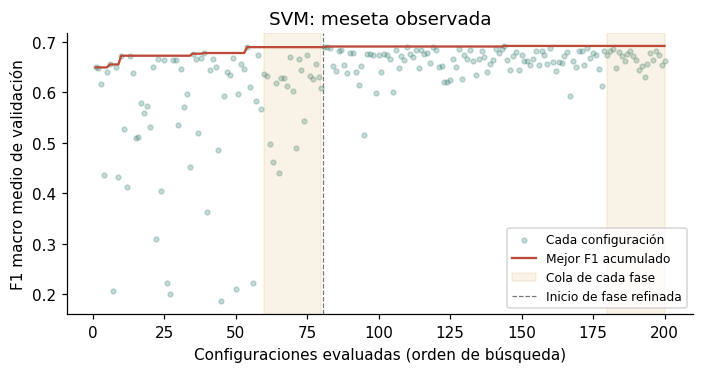

**SVM: parámetros elegidos por validación.**

,valor
features,FunctionTransformer(func=<function academic_fe...
features__kw_args,{'mode': 'rich'}
modelo,"SVC(C=np.float64(5.2055890131362235), cache_si..."
modelo__C,5.205589
modelo__class_weight,"{'dropout': 1.2, 'enrolled': 2.0, 'graduate': ..."
modelo__gamma,0.002317
pre,"ColumnTransformer(sparse_threshold=0,\n ..."
pre__cat__codificar__min_frequency,None
pre__transformer_weights,"{'cat': 1.5, 'num': 1.0}"
pipeline_efectivo,"Pipeline(steps=[('features',\n ..."


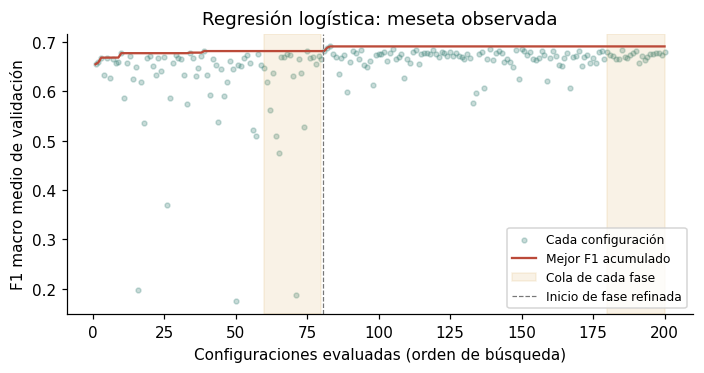

**Regresión logística: parámetros elegidos por validación.**

,valor
features,FunctionTransformer(func=<function academic_fe...
features__kw_args,{'mode': 'rich'}
modelo,"LogisticRegression(C=0.0416031769123584,\n ..."
modelo__C,0.041603
modelo__class_weight,"{'dropout': 1.2, 'enrolled': 2.0, 'graduate': ..."
pre,"ColumnTransformer(sparse_threshold=1.0,\n ..."
pre__cat__codificar__min_frequency,None
pre__transformer_weights,"{'cat': 1.0, 'num': 1.0}"
pipeline_efectivo,"Pipeline(steps=[('features',\n ..."


2193

In [6]:
busquedas_finales = {}
for nombre in ESPACIOS:
    print(f'Búsqueda final: {nombre}', flush=True)
    busquedas_finales[nombre] = buscar(
        nombre, X, y, CV_EXTERNA, minimo_refinado=MIN_REFINADA_FINAL)

mesetas = pd.DataFrame([
    {'modelo': n, 'n_config': r['n_config'], 'mejor_f1_seleccion': r['f1_seleccion'],
     'ganancia_maxima_cola_por_fase': r['ganancia_cola'], 'meseta': r['meseta'],
     'fase_seleccionada': r['fase_seleccionada'],
     'configuraciones_por_fase': json.dumps({
         f['fase']: f['n_config'] for f in r['fases']}),
     'segundos_busqueda_final': r['segundos']}
    for n, r in busquedas_finales.items()
]).set_index('modelo')
display(mesetas.round(5))
for i, (nombre, r) in enumerate(busquedas_finales.items(), start=1):
    historial = r['historial']
    historial.drop(columns=['params']).to_csv(
        SALIDAS / f'busqueda_modelo_{i}.csv', index=False)
    scores = historial['mean_test_score'].to_numpy()
    fig, ax = plt.subplots(figsize=(6.5, 3.5))
    ax.scatter(np.arange(1, len(scores)+1), scores, s=10, alpha=0.25,
               color='#28756a', label='Cada configuración')
    ax.plot(np.arange(1, len(scores)+1), np.maximum.accumulate(scores),
            color='#bb4a39', label='Mejor F1 acumulado')
    for j, (fase, grupo) in enumerate(historial.groupby('fase', sort=False)):
        final_fase = int(grupo['configuracion_global'].max())
        inicio_fase = int(grupo['configuracion_global'].min())
        ax.axvspan(final_fase - VENTANA_MESETA, final_fase, color='#d09a35',
                   alpha=0.12, label='Cola de cada fase' if j == 0 else None)
        if j:
            ax.axvline(inicio_fase - 0.5, color='#777777', linestyle='--',
                       linewidth=0.8, label='Inicio de fase refinada')
    ax.set(xlabel='Configuraciones evaluadas (orden de búsqueda)',
           ylabel='F1 macro medio de validación',
           title=f'{nombre}: ' + ('meseta observada' if r['meseta'] else 'límite sin meseta'))
    ax.legend(fontsize=8, loc='lower right')
    fig.tight_layout()
    fig.savefig(SALIDAS / f'meseta_modelo_{i}.png', dpi=180)
    plt.show()
    display(Markdown(f'**{nombre}: parámetros elegidos por validación.**'))
    display(pd.Series(legible(r['params']), dtype=object).to_frame('valor'))

comparacion = comparacion.join(mesetas[['segundos_busqueda_final', 'n_config', 'meseta']])
comparacion.to_csv(SALIDAS / 'comparacion_modelos.csv')
mesetas.to_csv(SALIDAS / 'mesetas.csv')
(SALIDAS / 'mejores_parametros.json').write_text(json.dumps(
    {n: legible(r['params']) for n, r in busquedas_finales.items()},
    ensure_ascii=False, indent=2), encoding='utf-8')

(SALIDAS / 'detalle_fases_finales.json').write_text(json.dumps(
    {n: {'fase_seleccionada': r['fase_seleccionada'], 'fases': r['fases']}
     for n, r in busquedas_finales.items()},
    ensure_ascii=False, indent=2), encoding='utf-8')


Matriz de confusión y análisis de desertores

La matriz usa únicamente predicciones externas de validación cruzada anidada.
Las filas son las etiquetas reales y las columnas las predicciones. La tabla de
errores identifica la confusión predominante sin presuponer que sea con inscritos.
El perfil académico compara grupos de desertores reales por su predicción; es un
análisis descriptivo posterior y no se utiliza para reentrenar o seleccionar variables.

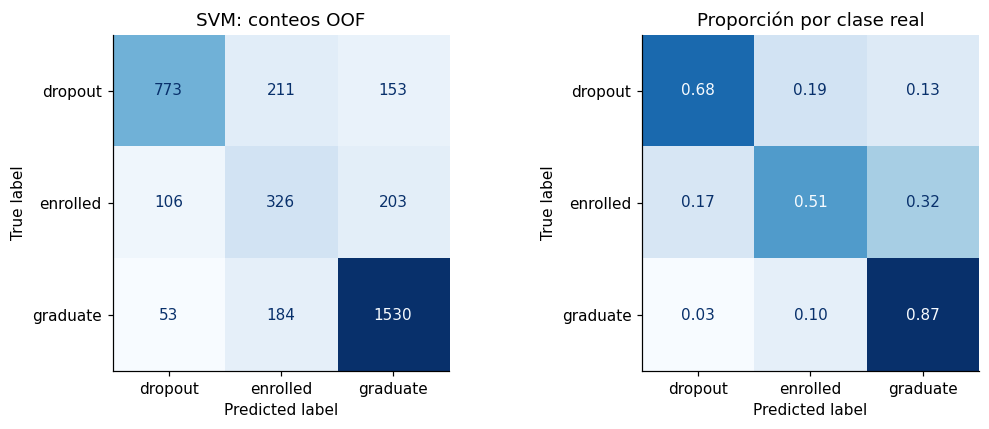

,clase,sensibilidad,especificidad
0,dropout,0.6799,0.9338
1,enrolled,0.5134,0.8640
2,graduate,0.8659,0.7991


,desertores_confundidos
enrolled,211
graduate,153


,n,Curricular units 1st sem (approved),Curricular units 1st sem (enrolled),Curricular units 1st sem (grade),Tuition fees up to date,Debtor
predicción_oof,,,,,,
dropout,773,1.620,5.715,5.564,0.527,0.294
enrolled,211,3.616,5.934,11.178,0.981,0.081
graduate,153,5.824,6.294,11.074,0.980,0.072


La confusión más frecuente de desertores es con **enrolled**: 211 casos, 18.6% de los desertores reales. La clase enrolled incluye estudiantes que no han terminado al horizonte de observación; un avance académico parcial puede parecerse al de quienes finalmente abandonan. Un desertor también puede aprobar al principio y abandonar después por circunstancias no observadas. Estas son hipótesis compatibles con el horizonte y el perfil mostrado, no causas demostradas.

In [7]:
pred_mejor = resultados_cv[mejor_nombre]['oof']
cm = confusion_matrix(y, pred_mejor, labels=CLASES)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=axes[0], cmap='Blues', colorbar=False)
normalizada = cm / cm.sum(axis=1, keepdims=True)
ConfusionMatrixDisplay(normalizada, display_labels=CLASES).plot(
    ax=axes[1], cmap='Blues', colorbar=False, values_format='.2f')
axes[0].set_title(f'{mejor_nombre}: conteos OOF')
axes[1].set_title('Proporción por clase real')
fig.tight_layout()
fig.savefig(SALIDAS / 'matriz_confusion_mejor.png', dpi=180)
plt.show()
pd.DataFrame(cm, index=CLASES, columns=CLASES).to_csv(
    SALIDAS / 'matriz_confusion_mejor.csv', index_label='real')
display(metricas_clase(y, pred_mejor).round(4))
errores_dropout = pd.Series(cm[0, 1:], index=CLASES[1:], name='desertores_confundidos')
display(errores_dropout.to_frame())
perfil = X.loc[y.eq('dropout'), [
    'Curricular units 1st sem (approved)', 'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (grade)', 'Tuition fees up to date', 'Debtor',
]].copy()
perfil['predicción_oof'] = pred_mejor[y.eq('dropout').to_numpy()]
perfil_medias = perfil.groupby('predicción_oof').mean().round(3)
perfil_medias.insert(0, 'n', perfil.groupby('predicción_oof').size())
display(perfil_medias)
perfil_medias.to_csv(SALIDAS / 'perfil_desertores.csv')
destino = errores_dropout.idxmax()
if errores_dropout.sum() == 0:
    texto_error = 'No hubo desertores clasificados en otra clase en estos pliegues.'
else:
    texto_error = (
        f'La confusión más frecuente de desertores es con **{destino}**: '
        f'{int(errores_dropout[destino])} casos, '
        f'{100 * errores_dropout[destino] / cm[0].sum():.1f}% de los desertores reales. '
        'La clase enrolled incluye estudiantes que no han terminado al horizonte de '
        'observación; un avance académico parcial puede parecerse al de quienes '
        'finalmente abandonan. Un desertor también puede aprobar al principio y '
        'abandonar después por circunstancias no observadas. Estas son hipótesis '
        'compatibles con el horizonte y el perfil mostrado, no causas demostradas.'
    )
display(Markdown(texto_error))

¿Cuánto mejoraría esperar al segundo semestre?

Se repite **la misma familia ganadora del primer semestre**, con el mismo espacio
de búsqueda, criterio de meseta y pliegues externos e internos, agregando solamente
las seis variables del segundo semestre. Se reoptimiza dentro de cada ajuste para
comparar versiones adaptadas a cada horizonte. La diferencia de F1 y sensibilidad
de desertores se calcula de forma pareada por pliegue. No se usa el conjunto de prueba.
La comparación estima el valor predictivo de información posterior dentro de esta
cohorte; no mide el efecto causal de esperar ni de una intervención.

SVM / original: inicio, minimo=80, maximo=160


SVM / original: 80 configuraciones, mejor F1=0.718743, ganancia=0.000000


SVM / refinada: inicio, minimo=80, maximo=160


SVM / refinada: 80 configuraciones, mejor F1=0.726835, ganancia=0.000000


SVM: externo 1/5, F1=0.7155, configuraciones=160


SVM / original: inicio, minimo=80, maximo=160


... (17 outputs left out)

SVM / refinada: inicio, minimo=80, maximo=160


SVM / refinada: 80 configuraciones, mejor F1=0.721657, ganancia=0.000636


SVM: externo 5/5, F1=0.7309, configuraciones=160


,pliegue,f1_macro_s1,f1_macro_s2,delta_f1,sensibilidad_s1,sensibilidad_s2,delta_sensibilidad_dropout
0,1,0.6893,0.7155,0.0262,0.6211,0.6960,0.0749
1,2,0.6870,0.7229,0.0359,0.7004,0.6828,-0.0176
2,3,0.6815,0.7266,0.0451,0.6886,0.7763,0.0877
3,4,0.6781,0.7211,0.0430,0.6754,0.7149,0.0395
4,5,0.7054,0.7309,0.0254,0.7137,0.7313,0.0176


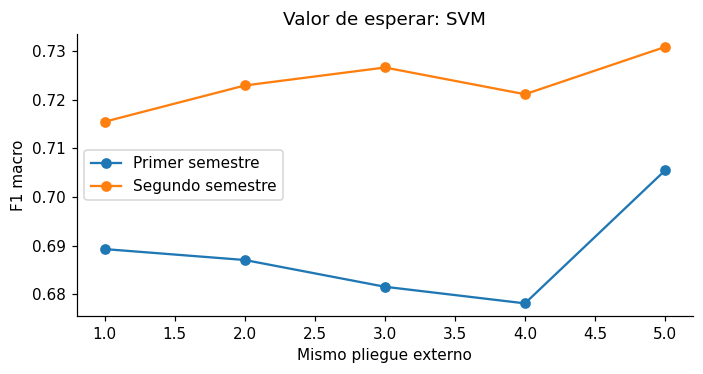

Agregar el segundo semestre cambia F1 macro en **+0.0351 ± 0.0092** (+3.51 puntos porcentuales, media ± DE de diferencias), y la sensibilidad de desertores en **+0.0404**. La diferencia de F1 es positiva en 5 de 5 pliegues. Estos pliegues comparten estudiantes en sus ajustes: la DE no es una prueba de significancia ni un intervalo de confianza. La información adicional mejora la media de esta evaluación, pero esperar retrasa un semestre cualquier apoyo. Para alertas tempranas conviene actuar con el primer semestre y actualizar la evaluación en el segundo. Una decisión institucional de posponer acciones requiere costos de errores, tiempos de abandono y eficacia de apoyos, datos que aquí no conocemos. No se toma la opción de esperar únicamente por maximizar F1.

In [8]:
resultado_s2 = evaluar_anidado(mejor_nombre, X2)
pareada = resultados_cv[mejor_nombre]['pliegues'][['pliegue', 'f1_macro']].merge(
    resultado_s2['pliegues'][['pliegue', 'f1_macro']], on='pliegue',
    suffixes=('_s1', '_s2'), validate='one_to_one')
pareada['delta_f1'] = pareada['f1_macro_s2'] - pareada['f1_macro_s1']
d1 = resultados_cv[mejor_nombre]['clases'].query("clase == 'dropout'")[
    ['pliegue', 'sensibilidad']]
d2 = resultado_s2['clases'].query("clase == 'dropout'")[['pliegue', 'sensibilidad']]
pareada = pareada.merge(d1, on='pliegue').merge(d2, on='pliegue', suffixes=('_s1', '_s2'))
pareada['delta_sensibilidad_dropout'] = pareada['sensibilidad_s2'] - pareada['sensibilidad_s1']
display(pareada.round(4))
pareada.to_csv(SALIDAS / 'comparacion_semestres_pareada.csv', index=False)
fig, ax = plt.subplots(figsize=(6.5, 3.5))
for etiqueta, col in [('Primer semestre', 'f1_macro_s1'), ('Segundo semestre', 'f1_macro_s2')]:
    ax.plot(pareada['pliegue'], pareada[col], marker='o', label=etiqueta)
ax.set(xlabel='Mismo pliegue externo', ylabel='F1 macro', title=f'Valor de esperar: {mejor_nombre}')
ax.legend()
fig.tight_layout()
fig.savefig(SALIDAS / 'comparacion_semestres.png', dpi=180)
plt.show()
delta = pareada['delta_f1'].mean()
delta_sd = pareada['delta_f1'].std(ddof=1)
delta_rec = pareada['delta_sensibilidad_dropout'].mean()
display(Markdown(
    f'Agregar el segundo semestre cambia F1 macro en **{delta:+.4f} ± {delta_sd:.4f}** '
    f'({100 * delta:+.2f} puntos porcentuales, media ± DE de diferencias), '
    f'y la sensibilidad de desertores en **{delta_rec:+.4f}**. '
    f'La diferencia de F1 es positiva en {int((pareada["delta_f1"] > 0).sum())} '
    f'de {N_EXTERNOS} pliegues. '
    'Estos pliegues comparten estudiantes en sus ajustes: la DE no es una prueba '
    'de significancia ni un intervalo de confianza. '
    + ('La información adicional mejora la media de esta evaluación, pero ' if delta > 0 else
       'No se observa una mejora media que justifique esperar en esta evaluación; ')
    + 'esperar retrasa un semestre cualquier apoyo. Para alertas tempranas conviene '
    'actuar con el primer semestre y actualizar la evaluación en el segundo. '
    'Una decisión institucional de posponer acciones requiere costos de errores, '
    'tiempos de abandono y eficacia de apoyos, datos que aquí no conocemos. '
    'No se toma la opción de esperar únicamente por maximizar F1.'
))

Modelo final y archivo de entrega

La familia se elige mediante el F1 macro externo medio del **primer semestre**;
sus hiperparámetros son los de su búsqueda final sobre entrenamiento. Se ajusta
una sola vez con los 3539 estudiantes y exclusivamente sus 30 atributos disponibles.
Las seis columnas posteriores no entran en este ajuste. Se conservan los IDs y el
orden original de prueba. El notebook relee el CSV generado para comprobar el contrato
de entrega: 885 filas y exactamente `id,Target`, con etiquetas en minúsculas.

In [9]:
modelo_final = construir_estimador(busquedas_finales[mejor_nombre]['params'])
with threadpool_limits(limits=1), warnings.catch_warnings():
    warnings.simplefilter('error', ConvergenceWarning)
    modelo_final.fit(X, y)
    predicciones = modelo_final.predict(X_test)
entrega = pd.DataFrame({'id': test['id'].copy(), 'Target': predicciones})
assert entrega.shape == (885, 2) and list(entrega) == ['id', 'Target']
assert entrega['id'].equals(test['id']) and entrega['id'].is_unique
assert entrega['Target'].isin(CLASES).all() and not entrega.isna().any().any()
ARCHIVO_ENTREGA = BASE / 'predicciones_desercion.csv'
entrega.to_csv(ARCHIVO_ENTREGA, index=False, encoding='utf-8')
verificacion = pd.read_csv(ARCHIVO_ENTREGA, dtype={'id': 'string'})
pd.testing.assert_frame_equal(entrega, verificacion)
display(entrega.head())
display(entrega['Target'].value_counts().reindex(CLASES, fill_value=0).to_frame('predicciones'))
print(f'CSV generado y comprobado: {ARCHIVO_ENTREGA.as_posix()} ({len(entrega)} filas)')

,id,Target
0,6,graduate
1,12,graduate
2,15,graduate
3,18,graduate
4,19,graduate


,predicciones
Target,
dropout,218
enrolled,194
graduate,473


CSV generado y comprobado: Practicas/predicciones_desercion.csv (885 filas)


Discusión y conclusiones

Las cifras siguientes se calculan con los resultados de esta ejecución. Se comparan
familias optimizadas dentro de los espacios declarados: mejor no significa óptimo
global. La elección de candidatos entre fases usa F1 interno; la elección de familia
usa la media externa. No se promedian predicciones ni se forma un ensamble.

Los tiempos dependen del equipo, el paralelismo y el presupuesto efectivamente usado.
Una diferencia pequeña de F1 debe considerarse junto con la sensibilidad de desertores,
la especificidad y el costo de búsqueda. Las desviaciones entre pliegues no prueban
superioridad estadística. Los perfiles de errores describen asociaciones; sus
explicaciones se presentan como hipótesis y no establecen causas del abandono.

La ampliación del espacio y las características derivadas respetan el instante de
decisión. Aun así, desarrollar nuevas alternativas tras observar validación puede
generar optimismo; no conocemos el F1 de los estudiantes de prueba ni un techo de
desempeño de este problema. El paralelismo usa copias en memoria y cierra sus procesos
al terminar para evitar problemas de limpieza al cerrar Jupyter en Windows.

Nota de reproducción: los tiempos de la ejecución guardada se midieron con ocho
procesos (`loky`). La configuración de reproducción usa hilos (`threading`) para
evitar errores de limpieza de archivos temporales al cerrar procesos en Windows.
Se verificó con datos reales y dos pliegues que la configuración final de cada una
de las cinco familias produjo los mismos scores y predicciones con ambos backends.
Es un ajuste del transporte paralelo; las transformaciones, los clasificadores y
los hiperparámetros no cambian. Los tiempos pueden variar con el backend y el equipo.


In [10]:
explicaciones = {
    'Árbol': 'Los cortes y la poda permiten relaciones no lineales e interpretación local; '
             'su variación entre pliegues ayuda a valorar la estabilidad del ajuste.',
    'Naive Bayes': 'Es una referencia probabilística rápida; su independencia condicional '
                   'puede ser restrictiva ante unidades inscritas, aprobadas y calificaciones relacionadas.',
    'kNN': 'Depende del escalamiento, de la distancia y de la densidad de cada clase; '
           'one-hot puede dispersar vecinos en un espacio de muchas dimensiones.',
    'SVM': 'Compara fronteras lineales y no lineales; C, gamma y pesos de clase '
           'controlan el equilibrio entre ajuste y generalización.',
    'Regresión logística': 'La regularización controla coeficientes en un espacio one-hot '
                          'amplio; su frontera lineal puede limitar interacciones no incluidas.',
}
parrafos = []
for nombre, fila in comparacion.iterrows():
    m = metricas.loc[nombre]
    sensible = m['sensibilidad_media'].idxmin()
    texto = (
        f'**{nombre}**: F1 macro externo {fila["f1_macro_media"]:.4f} ± '
        f'{fila["f1_macro_std"]:.4f}; sensibilidad de desertores '
        f'{m.loc["dropout", "sensibilidad_media"]:.4f} y especificidad de desertores '
        f'{m.loc["dropout", "especificidad_media"]:.4f}. '
        f'Su clase con menor sensibilidad es {sensible}. '
        f'La optimización anidada tardó {fila["segundos_busqueda_anidada"] / 60:.2f} min '
        f'y la búsqueda final {fila["segundos_busqueda_final"] / 60:.2f} min. '
        + explicaciones[nombre]
    )
    if nombre == 'Naive Bayes':
        texto += ' La variante seleccionada al usar todo entrenamiento fue ' + type(
            busquedas_finales[nombre]['params']['modelo']).__name__ + '.'
    parrafos.append(texto)
parrafos.append(
    f'El clasificador de entrega es **{mejor_nombre}**, entrenado con todos los '
    f'estudiantes de entrenamiento al primer semestre. {texto_error} '
    f'El cambio estimado al agregar el segundo semestre es {delta:+.4f} de F1 macro. '
    'Se recomienda usar la primera predicción para orientar una revisión de apoyo y '
    'actualizarla después; el modelo no demuestra causas ni debe decidir sanciones. '
    'No se conoce aquí el F1 de los 885 casos de prueba.'
)
parrafos.append(
    'Limitaciones: los pliegues estratificados mezclan cohortes y no estiman explícitamente '
    'generalización hacia un ciclo posterior. No hay año de ingreso para hacer un '
    'corte temporal. La disponibilidad de los atributos se toma de los CSV y de la '
    'consigna; la base no permite auditar sus marcas de tiempo individuales. '
    'La elección del ganador entre cinco familias usa los mismos resultados externos; '
    'su ventaja debe confirmarse en prueba. Una meseta local de búsqueda no demuestra '
    'que no existan otras configuraciones mejores.'
)

# Comparación contra los resultados reales archivados antes de refinar.
referencia_dir = SALIDAS / 'referencia_inicial'
referencia_meta = json.loads((referencia_dir / 'metadatos.json').read_text(encoding='utf-8'))
assert referencia_meta['huellas_datos_sha256'] == HUELLAS, 'La referencia usa otros datos.'
referencia = pd.read_csv(referencia_dir / 'comparacion_modelos.csv', index_col=0)
versiones = referencia[['f1_macro_media', 'f1_macro_std']].add_suffix('_inicial').join(
    comparacion[['f1_macro_media', 'f1_macro_std']].add_suffix('_actual'))
versiones['cambio_f1_macro'] = versiones['f1_macro_media_actual'] - versiones['f1_macro_media_inicial']
versiones.to_csv(SALIDAS / 'comparacion_versiones.csv')
ganador_inicial = referencia['f1_macro_media'].idxmax()
pliegues_iniciales = pd.read_csv(referencia_dir / 'metricas_pliegues.csv')
antes = pliegues_iniciales.loc[pliegues_iniciales['modelo'].eq(ganador_inicial),
    ['pliegue', 'f1_macro']].rename(columns={'f1_macro': 'f1_inicial'})
despues = pliegues.loc[pliegues['modelo'].eq(mejor_nombre),
    ['pliegue', 'f1_macro']].rename(columns={'f1_macro': 'f1_actual'})
comparacion_pareada_versiones = antes.merge(despues, on='pliegue', validate='one_to_one')
comparacion_pareada_versiones['cambio'] = comparacion_pareada_versiones['f1_actual'] - comparacion_pareada_versiones['f1_inicial']
assert len(comparacion_pareada_versiones) == N_EXTERNOS
comparacion_pareada_versiones.to_csv(SALIDAS / 'comparacion_versiones_pareada.csv', index=False)
resumen_mejora = {
    'familia_inicial': ganador_inicial, 'familia_actual': mejor_nombre,
    'f1_macro_inicial': float(referencia.loc[ganador_inicial, 'f1_macro_media']),
    'f1_macro_actual': float(comparacion.loc[mejor_nombre, 'f1_macro_media']),
    'cambio_pareado_medio': float(comparacion_pareada_versiones['cambio'].mean()),
    'cambio_pareado_std': float(comparacion_pareada_versiones['cambio'].std(ddof=1)),
    'pliegues_con_mejora': int(comparacion_pareada_versiones['cambio'].gt(0).sum()),
}
display(versiones.round(4))
display(comparacion_pareada_versiones.round(4))
parrafos.append(
    f'Frente a la entrega inicial, el F1 macro externo medio cambia de '
    f'{resumen_mejora["f1_macro_inicial"]:.4f} a '
    f'{resumen_mejora["f1_macro_actual"]:.4f}: '
    f'{100 * resumen_mejora["cambio_pareado_medio"]:+.2f} puntos porcentuales. '
    f'La diferencia es positiva en {resumen_mejora["pliegues_con_mejora"]} de '
    f'{N_EXTERNOS} pliegues. Es una comparación sobre los mismos datos y particiones, '
    'no una medición del F1 de prueba. La exploración previa orientó el nuevo espacio: '
    'la validación anidada mantiene separados los ajustes y las predicciones externas, '
    'pero la selección repetida de métodos puede introducir optimismo de desarrollo. '
    'La prueba del curso será la comprobación final de la mejora.'
)
nombre_lr = next(n for n in comparacion.index if n.startswith('Reg'))
parrafos.append(
    f'La SVM obtiene sensibilidad media de desertores '
    f'{metricas.loc[("SVM", "dropout"), "sensibilidad_media"]:.4f}; '
    f'logística obtiene {metricas.loc[(nombre_lr, "dropout"), "sensibilidad_media"]:.4f}. '
    'El criterio de selección de la entrega es F1 macro. Para una aplicación que '
    'priorizara encontrar desertores también habría que valorar esos errores y el '
    'tiempo de optimización. Las desviaciones entre pliegues no son una prueba de '
    'superioridad estadística.'
)
if {'graduate', 'dropout'} <= set(perfil_medias.index):
    aprobadas = 'Curricular units 1st sem (approved)'
    parrafos.append(
        f'Los desertores pronosticados como graduados aprobaron '
        f'{perfil_medias.loc["graduate", aprobadas]:.2f} unidades en promedio, frente a '
        f'{perfil_medias.loc["dropout", aprobadas]:.2f} entre los correctamente '
        'identificados como desertores. Un mayor avance inicial ayuda a entender '
        'esa confusión, porque no describe todas las circunstancias posteriores. '
        'Es una hipótesis compatible con el perfil observado, no una causa demostrada.'
    )

informe = '\n\n'.join(parrafos)
display(Markdown(informe))
(SALIDAS / 'conclusiones.md').write_text(informe, encoding='utf-8')
METADATOS = {
    'ejecucion_utc': datetime.now(timezone.utc).isoformat(), 'semilla': SEED,
    'semilla_refinamiento': SEMILLA_REFINAMIENTO,
    'versiones': VERSIONES, 'huellas_datos_sha256': HUELLAS,
    'filas_train': len(train), 'filas_test': len(test),
    'columnas_primer_semestre': columnas_s1, 'columnas_adicionales_segundo': SEGUNDO,
    'pliegues_externos': N_EXTERNOS, 'pliegues_internos': N_INTERNOS,
    'trabajadores_paralelos': N_JOBS, 'backend_cv': 'threading',
    'min_config_por_fase': MIN_CONFIG, 'max_config_por_fase': MAX_CONFIG,
    'min_config_refinada_final': MIN_REFINADA_FINAL,
    'fases_por_familia': {n: [f for f, _ in fases] for n, fases in FASES.items()},
    'presupuesto_por_familia': {
        n: {'minimo_anidado': MIN_CONFIG * len(fases),
            'minimo_final': MIN_CONFIG +
                (MIN_REFINADA_FINAL if len(fases) == 2 else 0),
            'maximo_total': MAX_CONFIG * len(fases)}
        for n, fases in FASES.items()},
    'criterio_meseta': {'ventana': VENTANA_MESETA, 'ganancia_maxima': TOL_MESETA},
    'modelo_final': mejor_nombre,
    'parametros_finales': legible(busquedas_finales[mejor_nombre]['params']),
    'configuraciones_evaluadas': {
        n: {'busqueda_final': r['n_config'],
            'cada_busqueda_interna': resultados_cv[n]['pliegues']['n_config'].tolist(),
            'fases_finales': r['fases'],
            'fase_final_seleccionada': r['fase_seleccionada'],
            'busquedas_externas': resultados_cv[n]['busquedas_externas']}
        for n, r in busquedas_finales.items()},
    'segundo_semestre': {'diferencia_f1_media': delta, 'diferencia_f1_std': delta_sd,
        'diferencia_sensibilidad_dropout_media': delta_rec,
        'configuraciones_internas': resultado_s2['pliegues']['n_config'].tolist(),
        'segundos_total': resultado_s2['segundos_total'],
        'parametros_externos': resultado_s2['parametros_externos'],
        'busquedas_externas': resultado_s2['busquedas_externas']},
    'parametros_externos_primer_semestre': {
        n: r['parametros_externos'] for n, r in resultados_cv.items()},
    'comparacion_version_inicial': resumen_mejora,
    'predicciones_sha256': hashlib.sha256(ARCHIVO_ENTREGA.read_bytes()).hexdigest(),
}
_ = (SALIDAS / 'metadatos.json').write_text(
    json.dumps(METADATOS, ensure_ascii=False, indent=2), encoding='utf-8')

,f1_macro_media_inicial,f1_macro_std_inicial,f1_macro_media_actual,f1_macro_std_actual,cambio_f1_macro
modelo,,,,,
SVM,0.6784,0.0138,0.6883,0.0106,0.0099
Regresión logística,0.6707,0.0072,0.6842,0.0057,0.0135
Árbol,0.6378,0.0128,0.6378,0.0128,0.0000
Naive Bayes,0.6104,0.0118,0.6104,0.0118,0.0000
kNN,0.5627,0.0121,0.5627,0.0121,0.0000


,pliegue,f1_inicial,f1_actual,cambio
0,1,0.6961,0.6893,-0.0068
1,2,0.6720,0.6870,0.0151
2,3,0.6858,0.6815,-0.0043
3,4,0.6596,0.6781,0.0185
4,5,0.6786,0.7054,0.0268


**SVM**: F1 macro externo 0.6883 ± 0.0106; sensibilidad de desertores 0.6799 y especificidad de desertores 0.9338. Su clase con menor sensibilidad es enrolled. La optimización anidada tardó 12.77 min y la búsqueda final 11.30 min. Compara fronteras lineales y no lineales; C, gamma y pesos de clase controlan el equilibrio entre ajuste y generalización.

**Regresión logística**: F1 macro externo 0.6842 ± 0.0057; sensibilidad de desertores 0.7009 y especificidad de desertores 0.9242. Su clase con menor sensibilidad es enrolled. La optimización anidada tardó 3.08 min y la búsqueda final 1.50 min. La regularización controla coeficientes en un espacio one-hot amplio; su frontera lineal puede limitar interacciones no incluidas.

**Árbol**: F1 macro externo 0.6378 ± 0.0128; sensibilidad de desertores 0.6297 y especificidad de desertores 0.9325. Su clase con menor sensibilidad es enrolled. La optimización anidada tardó 0.64 min y la búsqueda final 0.21 min. Los cortes y la poda permiten relaciones no lineales e interpretación local; su variación entre pliegues ayuda a valorar la estabilidad del ajuste.

**Naive Bayes**: F1 macro externo 0.6104 ± 0.0118; sensibilidad de desertores 0.6569 y especificidad de desertores 0.8410. Su clase con menor sensibilidad es enrolled. La optimización anidada tardó 0.45 min y la búsqueda final 0.16 min. Es una referencia probabilística rápida; su independencia condicional puede ser restrictiva ante unidades inscritas, aprobadas y calificaciones relacionadas. La variante seleccionada al usar todo entrenamiento fue CategoricalNB.

**kNN**: F1 macro externo 0.5627 ± 0.0121; sensibilidad de desertores 0.5831 y especificidad de desertores 0.9092. Su clase con menor sensibilidad es enrolled. La optimización anidada tardó 1.31 min y la búsqueda final 0.50 min. Depende del escalamiento, de la distancia y de la densidad de cada clase; one-hot puede dispersar vecinos en un espacio de muchas dimensiones.

El clasificador de entrega es **SVM**, entrenado con todos los estudiantes de entrenamiento al primer semestre. La confusión más frecuente de desertores es con **enrolled**: 211 casos, 18.6% de los desertores reales. La clase enrolled incluye estudiantes que no han terminado al horizonte de observación; un avance académico parcial puede parecerse al de quienes finalmente abandonan. Un desertor también puede aprobar al principio y abandonar después por circunstancias no observadas. Estas son hipótesis compatibles con el horizonte y el perfil mostrado, no causas demostradas. El cambio estimado al agregar el segundo semestre es +0.0351 de F1 macro. Se recomienda usar la primera predicción para orientar una revisión de apoyo y actualizarla después; el modelo no demuestra causas ni debe decidir sanciones. No se conoce aquí el F1 de los 885 casos de prueba.

Limitaciones: los pliegues estratificados mezclan cohortes y no estiman explícitamente generalización hacia un ciclo posterior. No hay año de ingreso para hacer un corte temporal. La disponibilidad de los atributos se toma de los CSV y de la consigna; la base no permite auditar sus marcas de tiempo individuales. La elección del ganador entre cinco familias usa los mismos resultados externos; su ventaja debe confirmarse en prueba. Una meseta local de búsqueda no demuestra que no existan otras configuraciones mejores.

Frente a la entrega inicial, el F1 macro externo medio cambia de 0.6784 a 0.6883: +0.99 puntos porcentuales. La diferencia es positiva en 3 de 5 pliegues. Es una comparación sobre los mismos datos y particiones, no una medición del F1 de prueba. La exploración previa orientó el nuevo espacio: la validación anidada mantiene separados los ajustes y las predicciones externas, pero la selección repetida de métodos puede introducir optimismo de desarrollo. La prueba del curso será la comprobación final de la mejora.

La SVM obtiene sensibilidad media de desertores 0.6799; logística obtiene 0.7009. El criterio de selección de la entrega es F1 macro. Para una aplicación que priorizara encontrar desertores también habría que valorar esos errores y el tiempo de optimización. Las desviaciones entre pliegues no son una prueba de superioridad estadística.

Los desertores pronosticados como graduados aprobaron 5.82 unidades en promedio, frente a 1.62 entre los correctamente identificados como desertores. Un mayor avance inicial ayuda a entender esa confusión, porque no describe todas las circunstancias posteriores. Es una hipótesis compatible con el perfil observado, no una causa demostrada.

Referencias

Realinho, V., Vieira Martins, M., Machado, J. y Baptista, L. (2021).
[Predict Students' Dropout and Academic Success](https://archive.ics.uci.edu/dataset/697).
UCI Machine Learning Repository. [DOI 10.24432/C5MC89](https://doi.org/10.24432/C5MC89).
Datos originales bajo CC BY 4.0 según UCI. La división de esta entrega proviene de
[husseinlopez/icd2026](https://github.com/husseinlopez/icd2026/tree/main/datos).

Documentación oficial de scikit-learn:
[validación anidada](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html),
[Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html),
[búsqueda aleatoria](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.ParameterSampler.html),
[Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html),
[CategoricalNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.CategoricalNB.html),
[regresión logística y regularización](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).

Joblib: [configuración del paralelismo y max_nbytes](https://joblib.readthedocs.io/en/stable/generated/joblib.parallel_config.html).

[ColumnTransformer y ponderación de grupos](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html), [OneHotEncoder y categorías infrecuentes](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html).

Preprocesamiento adicional: [OneHotEncoder y categorías infrecuentes](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html), [ColumnTransformer y ponderación de grupos](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html).